# Monsoon Rainfall & Flood-Risk Analysis for Multan Using ERA5 Reanalysis Data

**10-year trend analysis (2016-2025) + 2022 flood case study**

This notebook downloads, processes, and analyzes ERA5 hourly reanalysis data (total precipitation and 2m temperature) for Multan, Pakistan, to examine monsoon rainfall patterns and compare the 2022 flood year against the 10-year norm.

## Phase 1: Setup & Data Download

In [1]:
!pip install cdsapi netCDF4 --quiet

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
DATA_DIR = "/content/drive/MyDrive/ERA5_Multan"
os.makedirs(DATA_DIR, exist_ok=True)
print(f"Files will be saved to: {DATA_DIR}")

Mounted at /content/drive
Files will be saved to: /content/drive/MyDrive/ERA5_Multan


## Analysis-only mode (no CDS downloads)
This notebook reuses the previously extracted ERA5 NetCDF files in Google Drive. It does **not** initialize CDS credentials or request data. If any expected file is missing, it stops instead of downloading.


In [3]:
# No CDS key or API client needed: analysis-only mode.
print("Analysis-only mode: CDS downloads are disabled.")


Analysis-only mode: CDS downloads are disabled.


In [4]:
import os, glob
import xarray as xr

EXPECTED_FILES = [f"multan_{year}.nc" for year in [2016, 2017, 2018, 2019, 2020, 2021, 2023, 2024, 2025]] + ["multan_2022_full.nc"]
missing = [name for name in EXPECTED_FILES if not os.path.isfile(os.path.join(DATA_DIR, name))]
if missing:
    raise FileNotFoundError(
        "Analysis stopped; downloads are disabled. Missing input file(s) in "
        + DATA_DIR + ": " + ", ".join(missing)
    )
print(f"All {len(EXPECTED_FILES)} ERA5 files found. Continuing with existing data; no downloads.")


All 10 ERA5 files found. Continuing with existing data; no downloads.


In [5]:
nc_files = sorted(glob.glob(f"{DATA_DIR}/multan_*.nc"))
print(f"Found {len(nc_files)} netCDF files:")
for f in nc_files:
    print(" -", os.path.basename(f))

ds = xr.open_mfdataset(nc_files, combine="by_coords")
display(ds)

Found 10 netCDF files:
 - multan_2016.nc
 - multan_2017.nc
 - multan_2018.nc
 - multan_2019.nc
 - multan_2020.nc
 - multan_2021.nc
 - multan_2022_full.nc
 - multan_2023.nc
 - multan_2024.nc
 - multan_2025.nc


<xarray.Dataset> Size: 3MB
Dimensions:     (valid_time: 35112, latitude: 3, longitude: 3)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 281kB 2016-06-01 ... 2025-09-30T2...
  * latitude    (latitude) float64 24B 30.5 30.25 30.0
  * longitude   (longitude) float64 24B 71.25 71.5 71.75
    number      int64 8B 0
    expver      (valid_time) <U4 562kB dask.array<chunksize=(2928,), meta=np.ndarray>
Data variables:
    t2m         (valid_time, latitude, longitude) float32 1MB dask.array<chunksize=(2928, 3, 3), meta=np.ndarray>
    tp          (valid_time, latitude, longitude) float32 1MB dask.array<chunksize=(2928, 3, 3), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-08-17T14:27 GRIB to CDM+CF via cfgrib-0.9.1...

In [6]:
# Sanity check
print("Time range:", ds.valid_time.min().values, "to", ds.valid_time.max().values)
print("Missing tp values:", int(ds['tp'].isnull().sum().values), "out of", ds['tp'].size)
print("Missing t2m values:", int(ds['t2m'].isnull().sum().values), "out of", ds['t2m'].size)

Time range: 2016-06-01T00:00:00.000000000 to 2025-09-30T23:00:00.000000000
Missing tp values: 0 out of 316008
Missing t2m values: 0 out of 316008


## Phase 2: Extraction & Aggregation

In [7]:
import pandas as pd

# Average across the Multan grid box
ds_mean = ds.mean(dim=["latitude", "longitude"])

df = ds_mean.to_dataframe().reset_index()
df = df[["valid_time", "tp", "t2m"]].drop_duplicates(subset="valid_time")

df["precip_mm"] = df["tp"] * 1000        # meters -> millimeters
df["temp_c"] = df["t2m"] - 273.15        # Kelvin -> Celsius
df["time_pkt"] = df["valid_time"] + pd.Timedelta(hours=5)   # UTC -> Pakistan time

df = df.sort_values("time_pkt").reset_index(drop=True)
df.head()

,valid_time,tp,t2m,precip_mm,temp_c,time_pkt
0,2016-06-01 00:00:00,0.0,303.373413,0.0,30.223419,2016-06-01 05:00:00
1,2016-06-01 01:00:00,0.0,303.871338,0.0,30.721344,2016-06-01 06:00:00
2,2016-06-01 02:00:00,0.0,306.918091,0.0,33.768097,2016-06-01 07:00:00
3,2016-06-01 03:00:00,0.0,307.392944,0.0,34.242950,2016-06-01 08:00:00
4,2016-06-01 04:00:00,0.0,307.622681,0.0,34.472687,2016-06-01 09:00:00


In [8]:
df["date_pkt"] = df["time_pkt"].dt.date

daily = df.groupby("date_pkt").agg(
    precip_mm=("precip_mm", "sum"),
    temp_c=("temp_c", "mean")
).reset_index()

daily["date_pkt"] = pd.to_datetime(daily["date_pkt"])
daily["year"] = daily["date_pkt"].dt.year
daily["month"] = daily["date_pkt"].dt.month

daily_path = f"{DATA_DIR}/daily_data.csv"
daily.to_csv(daily_path, index=False)
print(f"Saved {daily_path} with {len(daily)} days of data")
daily.head(10)

Saved /content/drive/MyDrive/ERA5_Multan/daily_data.csv with 1473 days of data


,date_pkt,precip_mm,temp_c,year,month
0,2016-06-01,0.000000,37.286686,2016,6
1,2016-06-02,0.000689,35.226276,2016,6
2,2016-06-03,0.013987,37.271469,2016,6
3,2016-06-04,0.000000,37.599155,2016,6
4,2016-06-05,0.105699,38.040226,2016,6
5,2016-06-06,0.249439,38.157848,2016,6
6,2016-06-07,0.200325,37.973267,2016,6
7,2016-06-08,0.000000,37.056831,2016,6
8,2016-06-09,0.029405,36.870071,2016,6
9,2016-06-10,0.476201,36.667862,2016,6


In [9]:
monsoon = daily[daily["month"].isin([6, 7, 8, 9])]
yearly_totals = monsoon.groupby("year")["precip_mm"].sum().reset_index()
yearly_totals.columns = ["year", "monsoon_total_mm"]
print(yearly_totals)

   year  monsoon_total_mm
0  2016        186.810760
1  2017        218.156708
2  2018         84.673935
3  2019        224.595062
4  2020        252.345825
5  2021         53.380226
6  2022        374.207855
7  2023        145.055664
8  2024        274.651520
9  2025        190.788422


**Interpretation:** Monsoon rainfall totals swing widely year to year, from a low of ~53mm (2021) to a high of ~374mm (2022) - there is no clear steady increase or decrease across the decade (confirmed statistically in the trend analysis below).

## Phase 3: Trends, Extremes & Statistics

### Wettest single day, heavy-rain days, and dry spells per year

In [10]:
wettest_day_per_year = monsoon.loc[monsoon.groupby('year')['precip_mm'].idxmax()]
wettest_day_per_year = wettest_day_per_year[['year', 'date_pkt', 'precip_mm']].reset_index(drop=True)
wettest_day_per_year.columns = ['year', 'wettest_day_date', 'wettest_day_mm']
display(wettest_day_per_year)

,year,wettest_day_date,wettest_day_mm
0,2016,2016-08-27,22.153589
1,2017,2017-06-28,26.508650
2,2018,2018-07-20,7.911047
3,2019,2019-08-10,19.264751
4,2020,2020-08-31,104.288368
5,2021,2021-07-13,7.231236
6,2022,2022-06-21,46.697670
7,2023,2023-07-07,22.395929
8,2024,2024-08-17,42.713165
9,2025,2025-09-08,29.514524


In [11]:
heavy_rain_threshold = 10  # mm

all_years = sorted(monsoon['year'].unique())
heavy_rain_days_count = (
    monsoon[monsoon['precip_mm'] > heavy_rain_threshold]
    .groupby('year').size()
    .reindex(all_years, fill_value=0)
    .reset_index(name='heavy_rain_days_count')
)
heavy_rain_days_count.columns = ['year', 'heavy_rain_days_count']
display(heavy_rain_days_count)

,year,heavy_rain_days_count
0,2016,5
1,2017,8
2,2018,0
3,2019,7
4,2020,5
5,2021,0
6,2022,10
7,2023,5
8,2024,9
9,2025,7


In [12]:
dry_day_threshold = 1.0  # mm

def calculate_longest_dry_spell(series, dry_threshold):
    is_dry = (series < dry_threshold)
    if not is_dry.any():
        return 0
    dry_groups = is_dry.astype(int).groupby((~is_dry).cumsum()).cumsum()
    return dry_groups.max()

longest_dry_spells = []
for year, year_data in monsoon.groupby('year'):
    longest_spell = calculate_longest_dry_spell(year_data['precip_mm'], dry_day_threshold)
    longest_dry_spells.append({'year': year, 'longest_dry_spell_days': longest_spell})

longest_dry_spells_df = pd.DataFrame(longest_dry_spells)
display(longest_dry_spells_df)

,year,longest_dry_spell_days
0,2016,16
1,2017,18
2,2018,23
3,2019,26
4,2020,26
5,2021,30
6,2022,36
7,2023,50
8,2024,25
9,2025,25


### 2022 vs. the average of the other 9 years

In [13]:
year_2022 = 2022

wettest_2022 = wettest_day_per_year.loc[wettest_day_per_year['year'] == year_2022, 'wettest_day_mm'].iloc[0]
wettest_avg_others = wettest_day_per_year.loc[wettest_day_per_year['year'] != year_2022, 'wettest_day_mm'].mean()

heavy_2022 = heavy_rain_days_count.loc[heavy_rain_days_count['year'] == year_2022, 'heavy_rain_days_count'].iloc[0]
heavy_avg_others = heavy_rain_days_count.loc[heavy_rain_days_count['year'] != year_2022, 'heavy_rain_days_count'].mean()

dry_2022 = longest_dry_spells_df.loc[longest_dry_spells_df['year'] == year_2022, 'longest_dry_spell_days'].iloc[0]
dry_avg_others = longest_dry_spells_df.loc[longest_dry_spells_df['year'] != year_2022, 'longest_dry_spell_days'].mean()

total_2022 = yearly_totals.loc[yearly_totals['year'] == year_2022, 'monsoon_total_mm'].iloc[0]
total_avg_others = yearly_totals.loc[yearly_totals['year'] != year_2022, 'monsoon_total_mm'].mean()

print("2022 vs. average of other 9 years:\n")
print(f"Total monsoon rainfall:  2022 = {total_2022:.1f}mm   |  others avg = {total_avg_others:.1f}mm")
print(f"Wettest single day:      2022 = {wettest_2022:.1f}mm   |  others avg = {wettest_avg_others:.1f}mm")
print(f"Heavy rain days (>10mm): 2022 = {heavy_2022}          |  others avg = {heavy_avg_others:.1f}")
print(f"Longest dry spell:       2022 = {dry_2022} days       |  others avg = {dry_avg_others:.1f} days")

2022 vs. average of other 9 years:

Total monsoon rainfall:  2022 = 374.2mm   |  others avg = 181.2mm
Wettest single day:      2022 = 46.7mm   |  others avg = 31.3mm
Heavy rain days (>10mm): 2022 = 10          |  others avg = 5.1
Longest dry spell:       2022 = 36 days       |  others avg = 26.6 days


**Interpretation:** 2022 stands out clearly on total rainfall (374mm vs. ~181mm average) and on the frequency of heavy-rain days (10 vs. ~5), but its single wettest day (46.7mm) was *not* the most extreme in the dataset (2020 saw a 104mm day). This points to 2022 being driven by **persistent, repeated heavy rain across the season** rather than one catastrophic downpour - a distinction that matters for flood risk, since saturated ground amplifies the impact of each subsequent storm.

In [14]:
yearly_summary = (
    yearly_totals
    .merge(wettest_day_per_year, on='year')
    .merge(heavy_rain_days_count, on='year')
    .merge(longest_dry_spells_df, on='year')
)

summary_path = f"{DATA_DIR}/yearly_summary.csv"
yearly_summary.to_csv(summary_path, index=False)
print(f"Saved {summary_path}")
display(yearly_summary)

Saved /content/drive/MyDrive/ERA5_Multan/yearly_summary.csv


,year,monsoon_total_mm,wettest_day_date,wettest_day_mm,heavy_rain_days_count,longest_dry_spell_days
0,2016,186.810760,2016-08-27,22.153589,5,16
1,2017,218.156708,2017-06-28,26.508650,8,18
2,2018,84.673935,2018-07-20,7.911047,0,23
3,2019,224.595062,2019-08-10,19.264751,7,26
4,2020,252.345825,2020-08-31,104.288368,5,26
5,2021,53.380226,2021-07-13,7.231236,0,30
6,2022,374.207855,2022-06-21,46.697670,10,36
7,2023,145.055664,2023-07-07,22.395929,5,50
8,2024,274.651520,2024-08-17,42.713165,9,25
9,2025,190.788422,2025-09-08,29.514524,7,25


### Diurnal rainfall pattern (hour of day x month)

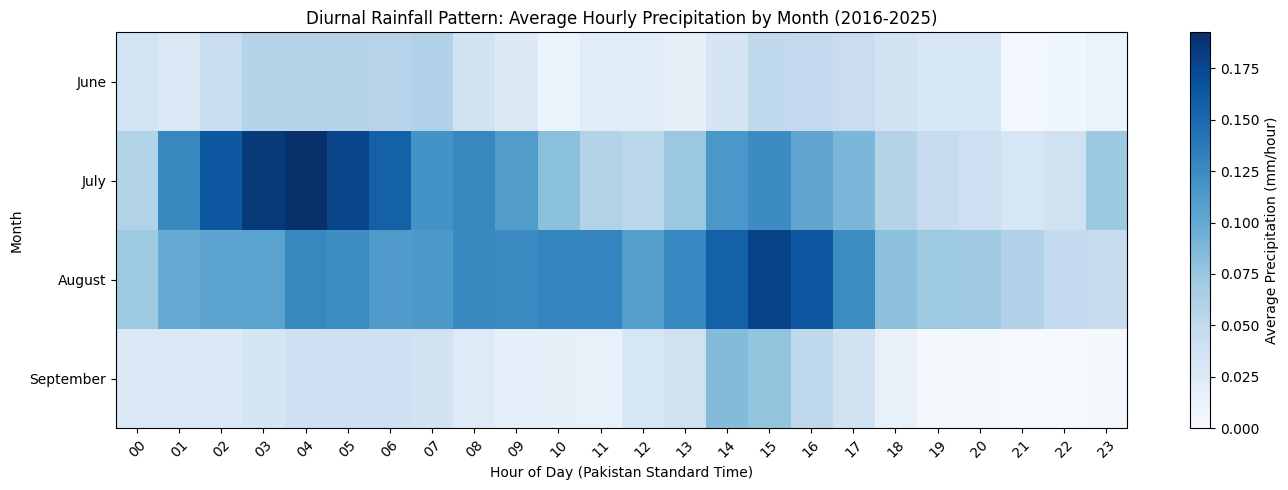

Hour with highest average rainfall across all monsoon months: 15:00 PKT


In [15]:
import numpy as np
import matplotlib.pyplot as plt

df['hour_pkt'] = df['time_pkt'].dt.hour
df['month_pkt'] = df['time_pkt'].dt.month
monsoon_hourly = df[df['month_pkt'].isin([6, 7, 8, 9])]

diurnal = monsoon_hourly.groupby(['month_pkt', 'hour_pkt'])['precip_mm'].mean().reset_index()
diurnal_pivot = diurnal.pivot(index='month_pkt', columns='hour_pkt', values='precip_mm')
diurnal_pivot = diurnal_pivot.reindex(index=[6, 7, 8, 9], columns=range(24), fill_value=0)

plt.figure(figsize=(14, 5))
im = plt.imshow(diurnal_pivot.values, aspect='auto', cmap='Blues', vmin=0)
plt.colorbar(im, label='Average Precipitation (mm/hour)')
plt.yticks(range(4), ['June', 'July', 'August', 'September'])
plt.xticks(range(24), [f'{h:02d}' for h in range(24)], rotation=45)
plt.xlabel('Hour of Day (Pakistan Standard Time)')
plt.ylabel('Month')
plt.title('Diurnal Rainfall Pattern: Average Hourly Precipitation by Month (2016-2025)')
plt.tight_layout()
plt.show()

overall_peak_hour = diurnal_pivot.mean(axis=0).idxmax()
print(f"Hour with highest average rainfall across all monsoon months: {overall_peak_hour:02d}:00 PKT")

**Interpretation:** Rainfall peaks around 15:00 PKT overall, with August in particular showing a strong mid-afternoon peak - consistent with typical late-afternoon convective monsoon storms in this region.

### Spatial patterns: daily/monthly time series, annual maps, anomalies, trend, extremes

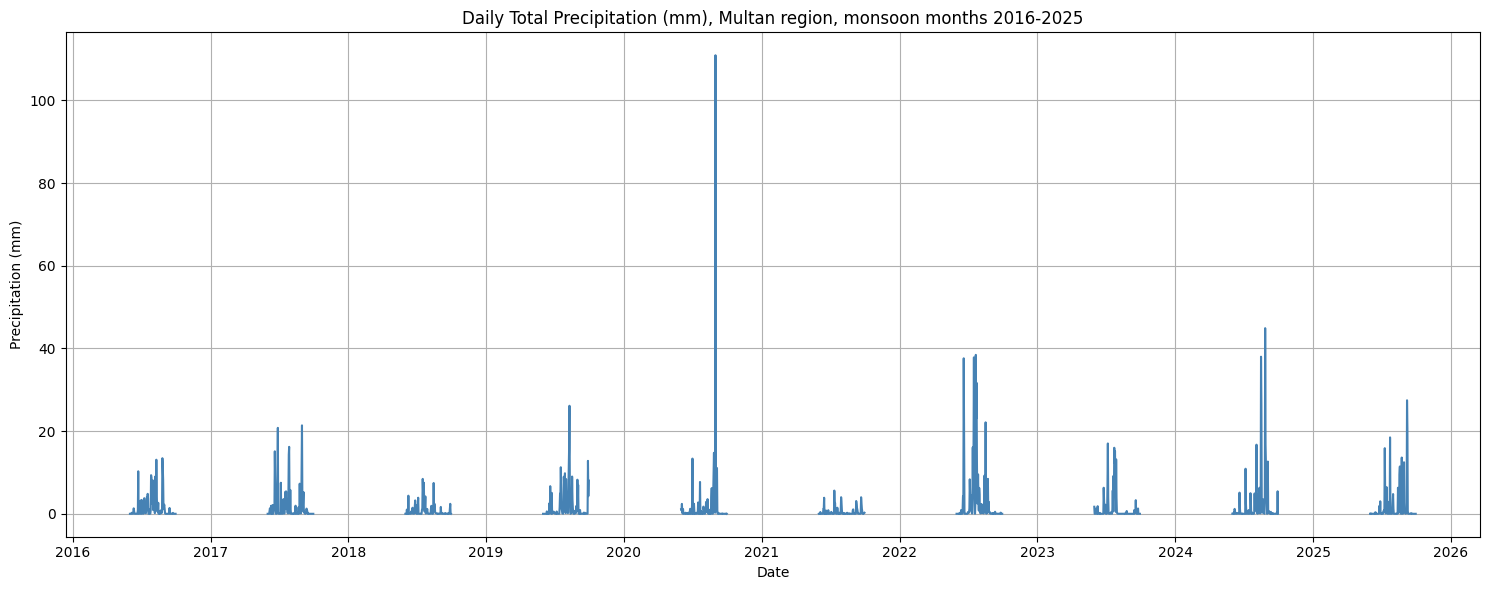

In [16]:
from scipy.stats import linregress

ds_monsoon = ds.sel(valid_time=ds['valid_time'].dt.month.isin([6, 7, 8, 9]))
precip_mm = ds_monsoon['tp'] * 1000
precip_mm.attrs['units'] = 'mm'

daily_precip_grid = precip_mm.resample(valid_time='1D').sum(dim='valid_time')

plt.figure(figsize=(15, 6))
daily_precip_grid.mean(dim=['latitude', 'longitude']).plot(color='steelblue')
plt.title('Daily Total Precipitation (mm), Multan region, monsoon months 2016-2025')
plt.xlabel('Date'); plt.ylabel('Precipitation (mm)')
plt.grid(True); plt.tight_layout(); plt.show()

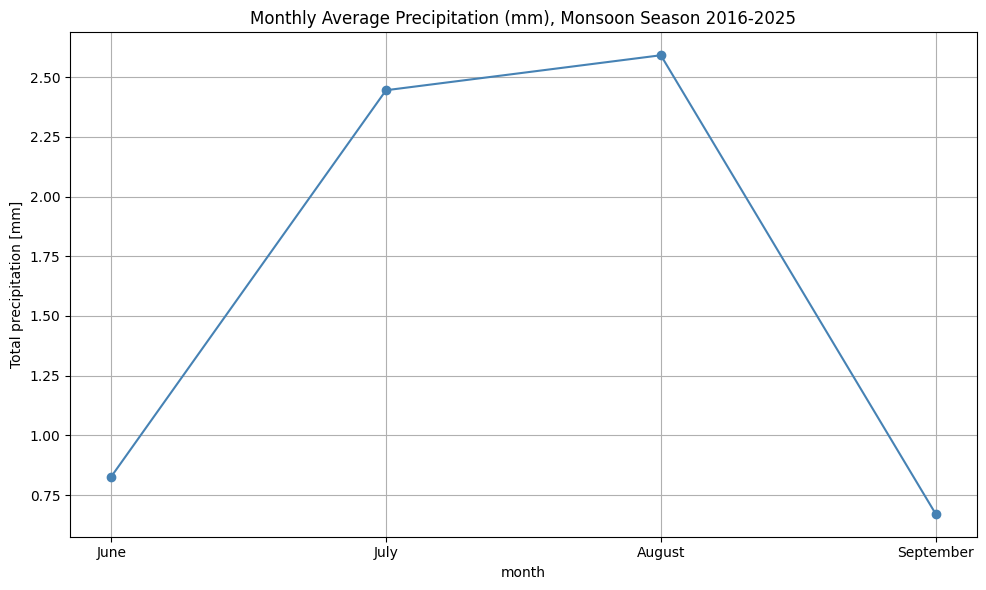

In [17]:
monthly_avg = daily_precip_grid.groupby('valid_time.month').mean(dim='valid_time')

plt.figure(figsize=(10, 6))
monthly_avg.mean(dim=['latitude', 'longitude']).plot(x='month', marker='o', color='steelblue')
plt.xticks([6, 7, 8, 9], ['June', 'July', 'August', 'September'])
plt.title('Monthly Average Precipitation (mm), Monsoon Season 2016-2025')
plt.grid(True); plt.tight_layout(); plt.show()

**Note on color scheme:** the two annual map cells below now use a **shared color scale** across all 10 panels (fixed to the dataset's true min/max), so colors are directly comparable year to year - unlike an earlier draft where each panel auto-scaled independently and made "yellow" mean different things in different years.

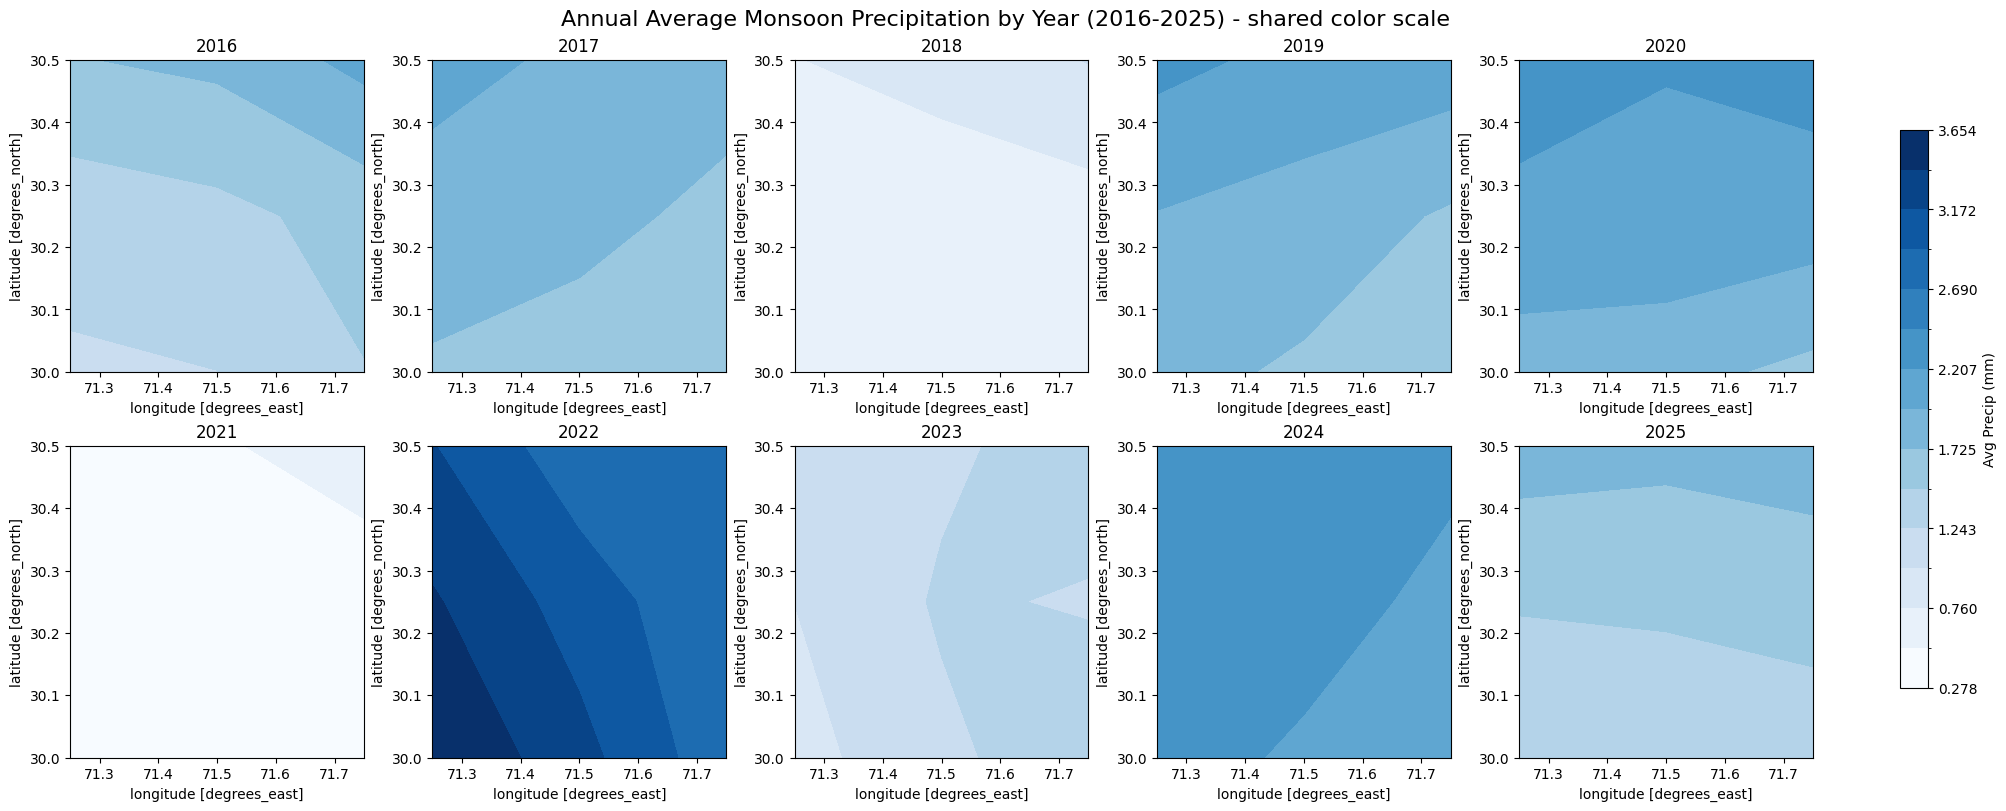

In [18]:
annual_avg = daily_precip_grid.groupby('valid_time.year').mean(dim='valid_time')

# Shared color scale across all panels so years are visually comparable
vmin = float(annual_avg.min().compute())
vmax = float(annual_avg.max().compute())
levels = np.linspace(vmin, vmax, 15)

fig, axes = plt.subplots(2, 5, figsize=(20, 8), constrained_layout=True)
axes = axes.flatten()
for i, year in enumerate(annual_avg.year.values):
    im = annual_avg.sel(year=year).plot.contourf(
        ax=axes[i], levels=levels, cmap='Blues', add_colorbar=False
    )
    axes[i].set_title(f'{int(year)}')
fig.colorbar(im, ax=axes, label='Avg Precip (mm)', shrink=0.8)
plt.suptitle('Annual Average Monsoon Precipitation by Year (2016-2025) - shared color scale', fontsize=16)
plt.show()

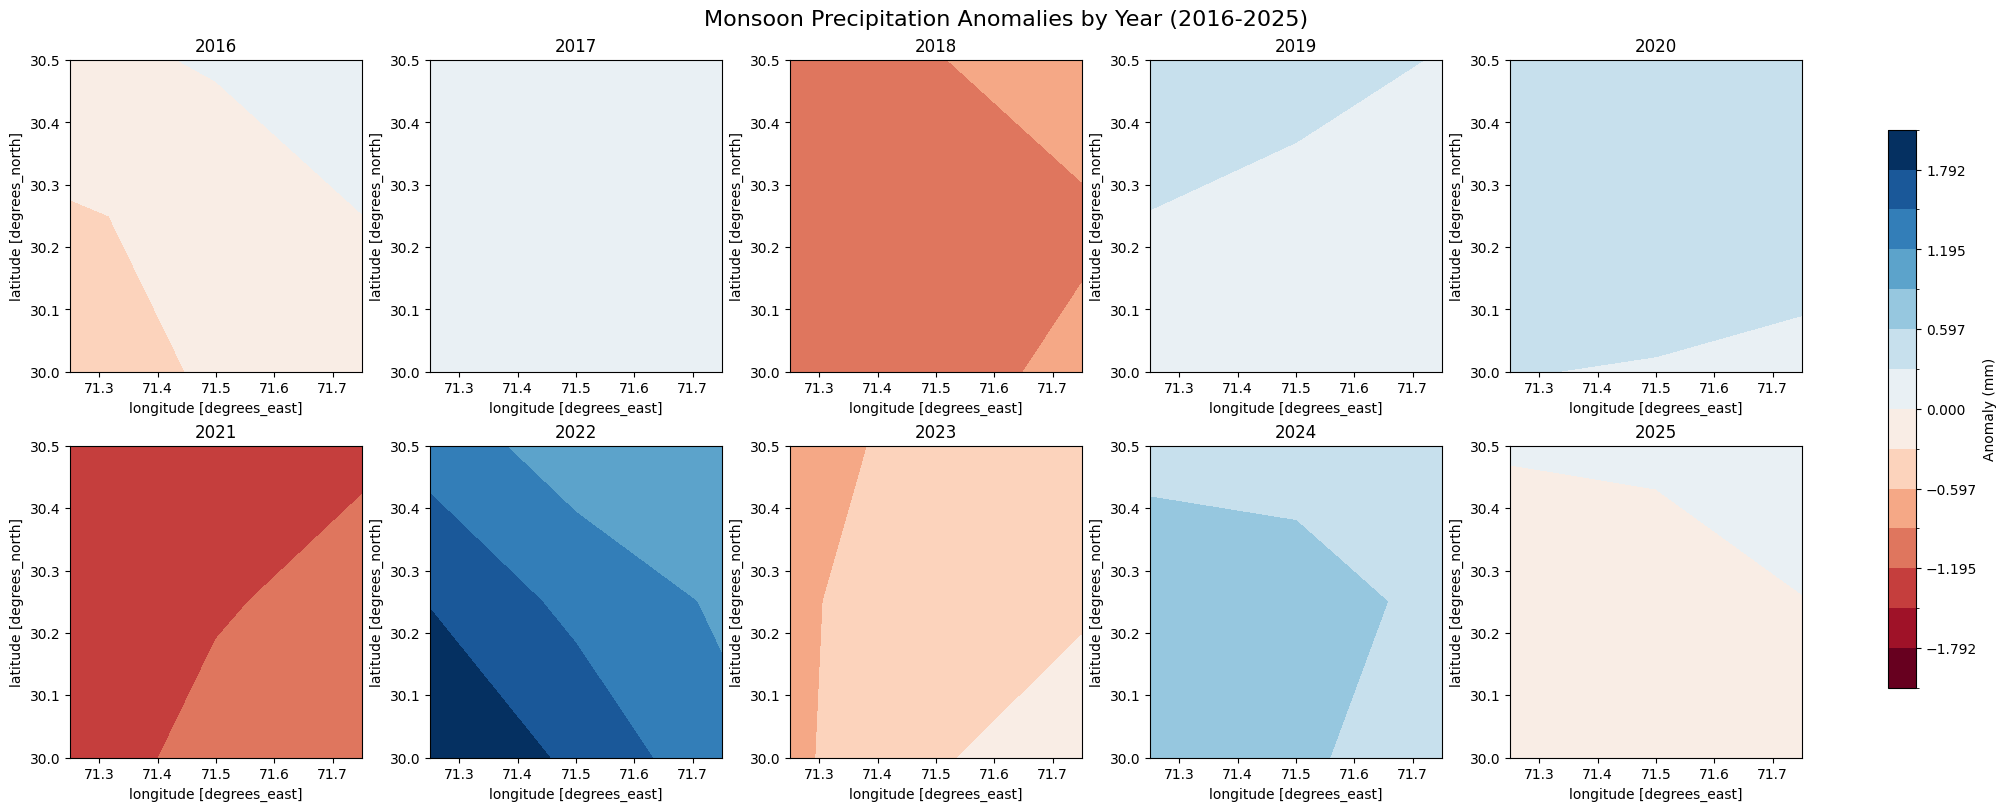

In [19]:
multi_year_avg = annual_avg.mean(dim='year')
anomalies = annual_avg - multi_year_avg
max_abs = float(np.abs(anomalies).max().compute())
levels = np.linspace(-max_abs, max_abs, 15)

fig, axes = plt.subplots(2, 5, figsize=(20, 8), constrained_layout=True)
axes = axes.flatten()
for i, year in enumerate(anomalies.year.values):
    im = anomalies.sel(year=year).plot.contourf(
        ax=axes[i], levels=levels, cmap='RdBu', add_colorbar=False
    )
    axes[i].set_title(f'{int(year)}')
fig.colorbar(im, ax=axes, label='Anomaly (mm)', shrink=0.8)
plt.suptitle('Monsoon Precipitation Anomalies by Year (2016-2025)', fontsize=16)
plt.show()

**Interpretation:** the anomaly maps show this decade's story is **volatility, not a directional trend** - 2021 is as extreme in deficit (white) as 2022 is in surplus (dark blue), with most other years sitting much closer to normal.

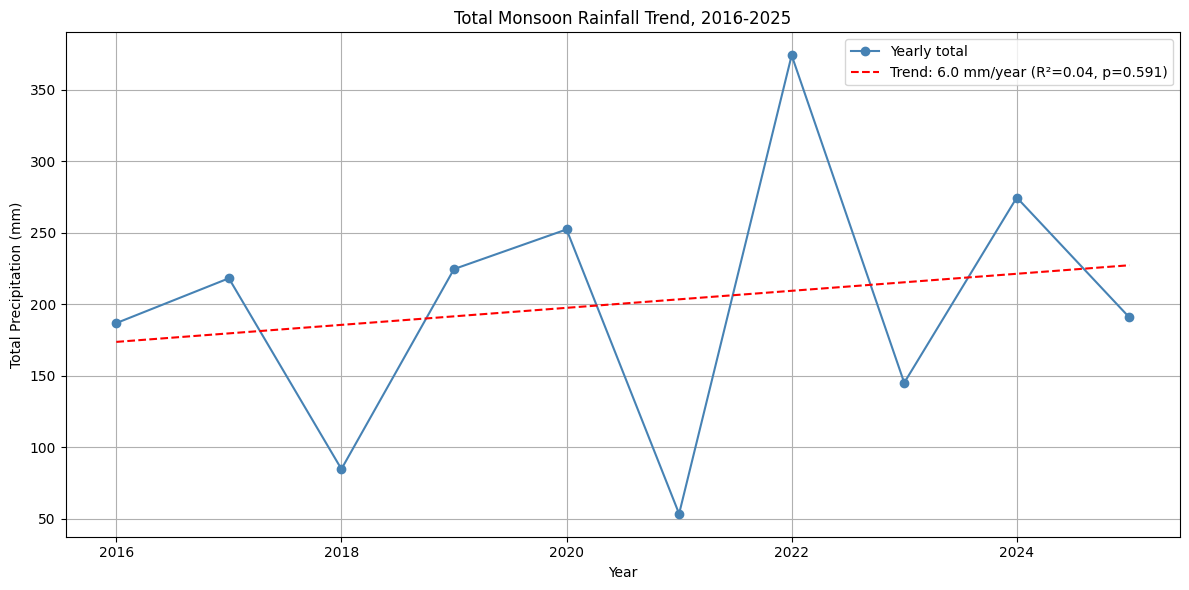

Slope: 5.96 mm/year | R2: 0.038 | p-value: 0.591


In [20]:
slope, intercept, r_value, p_value, std_err = linregress(
    yearly_totals['year'], yearly_totals['monsoon_total_mm']
)

plt.figure(figsize=(12, 6))
plt.plot(yearly_totals['year'], yearly_totals['monsoon_total_mm'], marker='o', color='steelblue', label='Yearly total')
plt.plot(yearly_totals['year'], intercept + slope * yearly_totals['year'], 'r--',
         label=f'Trend: {slope:.1f} mm/year (R²={r_value**2:.2f}, p={p_value:.3f})')
plt.title('Total Monsoon Rainfall Trend, 2016-2025')
plt.xlabel('Year'); plt.ylabel('Total Precipitation (mm)')
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

print(f"Slope: {slope:.2f} mm/year | R2: {r_value**2:.3f} | p-value: {p_value:.3f}")

**Interpretation (important):** the fitted trend line is **not statistically significant** - R² of ~0.04 means year-to-year variation explains under 4% of what's happening, and the p-value (~0.59) is far above the conventional 0.05 threshold. With only 10 years of data, this is consistent with the project's own stated limitation that a 10-year record is too short for formal climate trend detection. The honest finding is: **no significant trend, high year-to-year volatility.**

95th percentile threshold: 9.01 mm/day
Found 61 extreme days above that threshold:


,tp
valid_time,
2020-08-31,110.912804
2024-08-27,44.900257
2022-07-22,38.439434
2024-08-16,37.996185
2022-07-17,37.832840
...,...
2025-08-18,9.460768
2016-07-27,9.338538
2022-08-14,9.245555


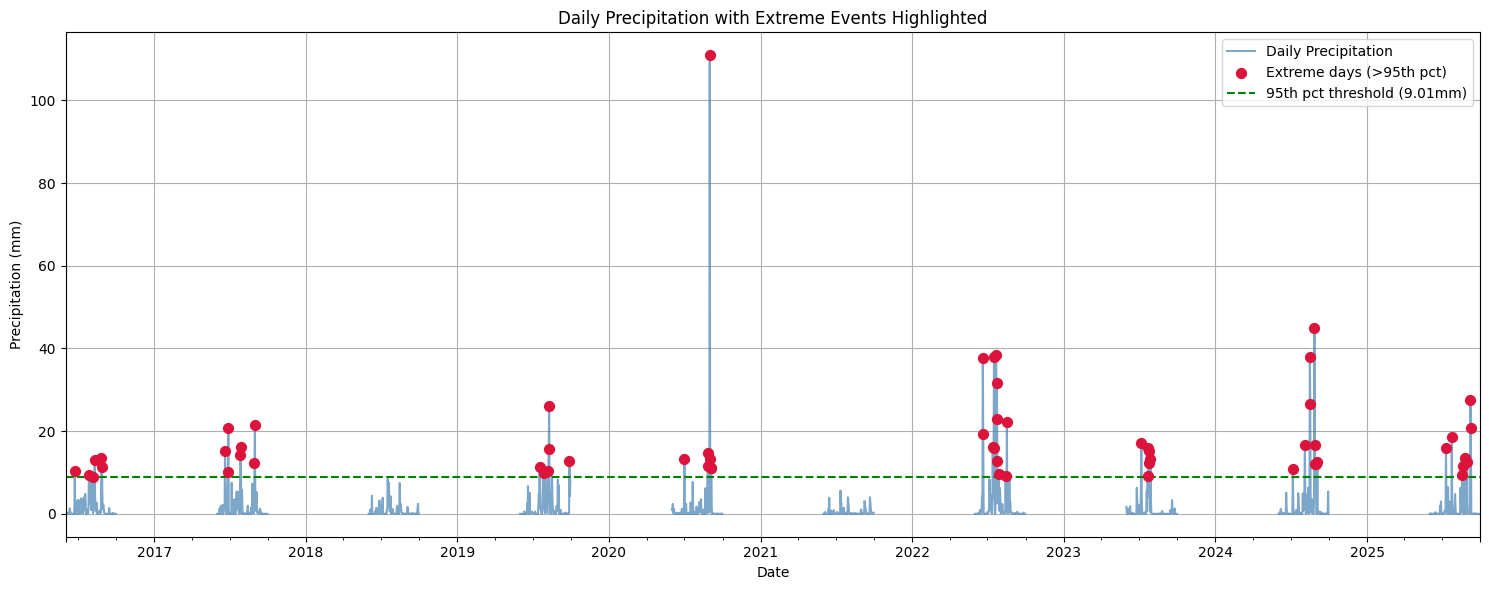

In [21]:
regional_daily = daily_precip_grid.mean(dim=['latitude', 'longitude']).to_series()
threshold = regional_daily.quantile(0.95)
extreme_days = regional_daily[regional_daily > threshold].sort_values(ascending=False)

print(f"95th percentile threshold: {threshold:.2f} mm/day")
print(f"Found {len(extreme_days)} extreme days above that threshold:")
display(extreme_days)

plt.figure(figsize=(15, 6))
regional_daily.plot(label='Daily Precipitation', color='steelblue', alpha=0.7)
plt.scatter(extreme_days.index, extreme_days.values, color='crimson', s=50, zorder=5, label='Extreme days (>95th pct)')
plt.axhline(y=threshold, color='green', linestyle='--', label=f'95th pct threshold ({threshold:.2f}mm)')
plt.title('Daily Precipitation with Extreme Events Highlighted')
plt.xlabel('Date'); plt.ylabel('Precipitation (mm)')
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

### Temperature: 2022 vs. the 10-year average (fills a gap in the original project plan)

The project's SMART objective calls for a full hourly rainfall *and temperature* record for 2022 compared against the 10-year average. Rainfall's side of that is covered above; here's the temperature side, which hadn't been built yet.

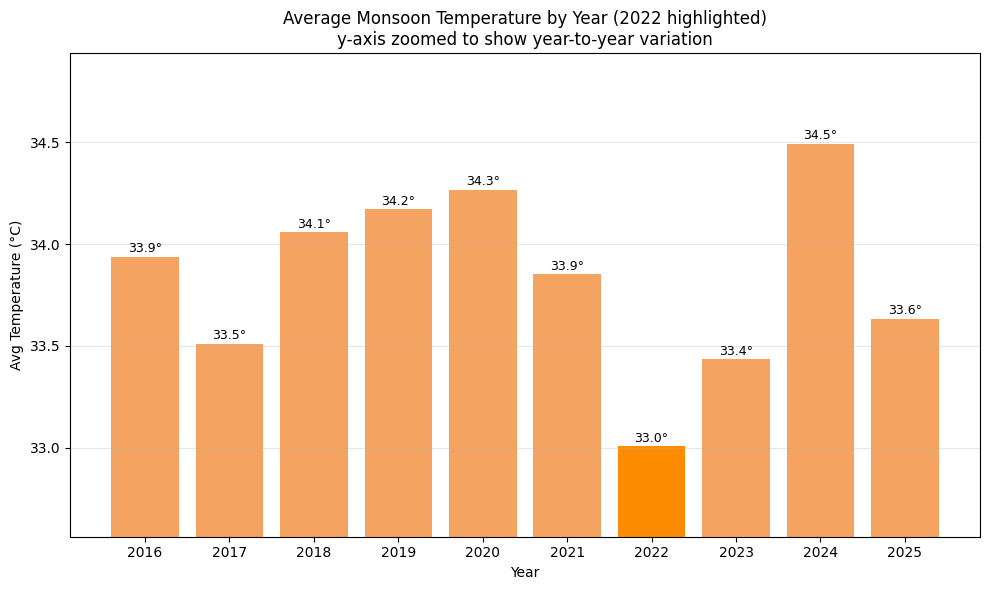

In [23]:
import matplotlib.pyplot as plt

# Calculate average temperature by year from the monsoon DataFrame to resolve the NameError
temp_by_year = monsoon.groupby('year')['temp_c'].mean().reset_index()
temp_by_year.columns = ['year', 'avg_temp_c']

plt.figure(figsize=(10, 6))
colors = ['darkorange' if y == 2022 else 'sandybrown' for y in temp_by_year['year']]
bars = plt.bar(temp_by_year['year'].astype(str), temp_by_year['avg_temp_c'], color=colors)

# Zoom the y-axis to the actual data range (with a little padding) instead of starting at 0
temp_min = temp_by_year['avg_temp_c'].min()
temp_max = temp_by_year['avg_temp_c'].max()
padding = (temp_max - temp_min) * 0.3
plt.ylim(temp_min - padding, temp_max + padding)

# Label each bar with its exact value, since the visual differences are now subtle
for bar, val in zip(bars, temp_by_year['avg_temp_c']):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + padding*0.05,
              f'{val:.1f}°', ha='center', fontsize=9)

plt.title('Average Monsoon Temperature by Year (2022 highlighted)\ny-axis zoomed to show year-to-year variation')
plt.xlabel('Year'); plt.ylabel('Avg Temperature (°C)')
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

In [ ]:
# 2022 full-year hourly temperature and rainfall time series (the case-study deliverable)
df_2022 = df[df['time_pkt'].dt.year == 2022].copy()

fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

axes[0].plot(df_2022['time_pkt'], df_2022['precip_mm'], color='steelblue', linewidth=0.7)
axes[0].set_ylabel('Precipitation (mm/hr)')
axes[0].set_title('2022 Full Year: Hourly Precipitation, Multan')
axes[0].grid(True)

axes[1].plot(df_2022['time_pkt'], df_2022['temp_c'], color='darkorange', linewidth=0.7)
axes[1].set_ylabel('Temperature (C)')
axes[1].set_xlabel('Date')
axes[1].set_title('2022 Full Year: Hourly Temperature, Multan')
axes[1].grid(True)

plt.tight_layout()
plt.show()

**Interpretation:** the 2022 flood period (visible as the dense cluster of rainfall spikes) coincides with the hottest part of the year - consistent with the known mechanism where intense pre-monsoon heat over Pakistan strengthens the monsoon low-pressure system and draws in more moisture.

## Phase 4: Summary

In [24]:
# Calculate 2022 and other years' average temperature from temp_by_year to avoid NameErrors
temp_2022 = temp_by_year.loc[temp_by_year['year'] == 2022, 'avg_temp_c'].iloc[0]
temp_avg_others = temp_by_year.loc[temp_by_year['year'] != 2022, 'avg_temp_c'].mean()

print("=== FINAL PROJECT SUMMARY: Multan Monsoon Rainfall, 2016-2025 ===\n")

print(f"Trend: {slope:.2f} mm/year (NOT statistically significant - R2={r_value**2:.3f}, p={p_value:.3f})")
print(f"2022 total monsoon rainfall: {total_2022:.1f}mm vs. {total_avg_others:.1f}mm average (other 9 years)")
print(f"2022 heavy-rain days (>10mm): {heavy_2022} vs. {heavy_avg_others:.1f} average")
print(f"2022 average temperature: {temp_2022:.1f}°C vs. {temp_avg_others:.1f}°C average")
print(f"\nPeak diurnal rainfall hour: {overall_peak_hour:02d}:00 PKT")
print(f"\nFiles saved to Google Drive ({DATA_DIR}):")
for f in sorted(glob.glob(f'{DATA_DIR}/*.csv')):
    print(' -', os.path.basename(f))

=== FINAL PROJECT SUMMARY: Multan Monsoon Rainfall, 2016-2025 ===

Trend: 5.96 mm/year (NOT statistically significant - R2=0.038, p=0.591)
2022 total monsoon rainfall: 374.2mm vs. 181.2mm average (other 9 years)
2022 heavy-rain days (>10mm): 10 vs. 5.1 average
2022 average temperature: 33.0°C vs. 33.9°C average

Peak diurnal rainfall hour: 15:00 PKT

Files saved to Google Drive (/content/drive/MyDrive/ERA5_Multan):
 - daily_data.csv
 - yearly_summary.csv


### Key findings

1. **No significant long-term trend** in monsoon rainfall over 2016-2025 (p=0.59) - the record is too short and too volatile for a defensible trend claim, consistent with the project's own stated limitations.
2. **2022 was an outlier in total volume and frequency of heavy rain**, not in single-day intensity - suggesting the flood was driven by sustained, repeated heavy rainfall (and resulting ground saturation) rather than one extreme event.
3. **2021 and 2022 bookend the decade** as the driest and wettest years respectively - the dominant pattern is volatility, not gradual change.
4. **Rainfall peaks in the mid-to-late afternoon** (around 15:00 PKT), consistent with typical convective monsoon storm timing.
5. **2022's flood period coincided with above-average heat**, consistent with known links between pre-monsoon heat and monsoon intensity.

### Stated limitations
- 10 years is short for formal climate trend detection (30+ years is the usual standard); results describe recent variability, not a long-term climate signal.
- ERA5's ~25km grid resolution represents a regional average around Multan, not a hyperlocal station reading.
- No spatial/terrain/flood-routing analysis was performed; this is a rainfall and temperature analysis only.